In [2]:
import pandas as pd
import numpy as np
import itertools

def triangular_mf(x, a, b, c):
    """
    Triangular membership function with foots a, c and peak b (degree 1 at b, 0 at a and c):contentReference[oaicite:3]{index=3}.
    """
    if x <= a or x >= c:
        return 0.0
    elif x <= b:
        return (x - a) / (b - a)  # rising edge
    else:
        return (c - x) / (c - b)  # falling edge

# Read dataset (assumed CSV with last column as binary decision)
filename = "brca.csv"
df = pd.read_csv(filename)

# Drop the first column
df = df.iloc[:, 1:]


# # Step 2: Drop unwanted columns
# columns_to_drop = ['x.radius_mean', 'x.texture_mean','x.perimeter_mean','x.area_mean','x.smoothness_mean','x.compactness_mean','x.concavity_mean','x.concave_pts_mean','x.symmetry_mean','x.fractal_dim_mean','x.radius_se','x.texture_se','x.perimeter_se','x.area_se','x.smoothness_se','x.compactness_se','x.concavity_se','x.concave_pts_se','x.symmetry_se','x.fractal_dim_se','x.radius_worst','x.texture_worst','x.perimeter_worst','x.area_worst']  # Replace with your actual column names
# df = df.drop(columns=columns_to_drop)


print(f"Loaded dataset '{filename}' with {df.shape[0]} samples and {df.shape[1]-1} features (plus 1 target).")

# Separate features and target
columns = list(df.columns)
target_col = columns[-1]
features = columns[:-1]
print(f"Features: {features}, Target: {target_col}")

# User-defined triangular membership parameters for each feature.
# Each entry: feature_name: [(a1, b1, c1), (a2, b2, c2)]
# Define two triangular MFs per feature.
membership_funcs = {
     'x.radius_mean': [(6, 12, 13.5), (12, 13.5, 29)],
     'x.texture_mean': [(9, 16, 18), (16, 18, 40)],
    'x.perimeter_mean': [(43, 74, 85), (75, 85, 190)],
    'x.area_mean': [(140, 400, 550), (400, 550, 2510)],
    'x.smoothness_mean': [(0.05, 0.1, 0.11), (0.1, 0.11, 0.17)],
    'x.compactness_mean': [(0.019, 0.052, 0.1), (0.052, 0.1, 0.3500)],
    'x.concavity_mean': [(0, 0.0014, 0.02), (0.0014, 0.02, 0.4300)],#Check
    'x.concave_pts_mean': [(0, 0.02, 0.04), (0.03, 0.04, 0.2100)],
    'x.symmetry_mean': [(0.100, 0.16, 0.2), (0.16, 0.2, 0.31)],
    'x.fractal_dim_mean': [(0.05, 0.06, 0.07), (0.06, 0.07, 0.1)],
    'x.radius_se': [(0.11, 0.18, 1), (0.18, 1, 2.9)], #Check
    'x.texture_se': [(0.35, 0.8, 1.5), (0.8, 1.5, 4.9)],
    'x.perimeter_se': [(0.8, 1, 10), (1, 10, 22)],
    'x.area_se': [(7, 10, 60), (10, 60, 550)],
    'x.smoothness_se': [(0.001, 0.005, 0.01), (0.005, 0.01, 0.033)],
    'x.compactness_se': [(0.002, 0.005, 0.1), (0.005, 0.1, 0.14)],
    'x.concavity_se': [(0, 0.2, 0.3), (0.2, 0.3, 0.4)],
    'x.concave_pts_se': [(0, 0.02, 0.04), (0.02, 0.04, 0.06)],
    'x.symmetry_se': [(0.007882, 0.04, 0.06), (0.04, 0.06, 0.08)],
    'x.fractal_dim_se': [(0.0008, 0.001, 0.015), (0.001, 0.015, 0.03)],
    'x.radius_worst': [(7.5, 10, 20), (10, 20, 37)],
    'x.texture_worst': [(12, 16, 18), (16, 18, 50)],
    'x.perimeter_worst': [(50, 56, 108), (56, 108, 252)],
    'x.area_worst': [(185, 216, 1018), (216, 1018, 4300)],
    'x.smoothness_worst': [(0.07, 0.1, 0.18), (0.1, 0.18, 0.23)],
    'x.compactness_worst': [(0.02729, 0.4, 0.9), (0.04, 0.9, 1.1)],
    'x.concavity_worst': [(0, 0.4, 0.7), (0.4, 0.7, 1.3)],
    'x.concave_pts_worst': [(0, 0.15, 0.25), (0.15, 0.25, 0.3)],
    'x.symmetry_worst': [(0.15, 0.4, 0.5), (0.4, 0.5, 0.67)],
    'x.fractal_dim_worst': [(0.055, 0.1, 0.2), (0.1, 0.2, 0.21)]
}

# Check that all features have membership parameters defined
for f in features:
    if f not in membership_funcs or len(membership_funcs[f]) != 2:
        raise ValueError(f"Membership functions for feature '{f}' are not defined properly.")

# Fuzzify all features: compute membership degrees for each sample
# Store mem_vals[f] = Nx2 array of membership degrees
N = df.shape[0]
mem_vals = {}
for f in features:
    a1, b1, c1 = membership_funcs[f][0]
    a2, b2, c2 = membership_funcs[f][1]
    mem_array = np.zeros((N, 2))
    for i, x in enumerate(df[f]):
        mem_array[i, 0] = triangular_mf(x, a1, b1, c1)
        mem_array[i, 1] = triangular_mf(x, a2, b2, c2)
    mem_vals[f] = mem_array
    # print(f"\nFeature '{f}' fuzzification:")
    for i in range(N):
        print(f"  Sample {i}: value={df[f][i]} -> μ1={mem_array[i,0]:.2f}, μ2={mem_array[i,1]:.2f}")

# Prepare target class memberships (crisp 0/1 for two classes)
classes = sorted(df[target_col].unique())
if len(classes) != 2:
    raise ValueError("Target column must be binary.")
class0, class1 = classes
mu_class0 = np.array([1.0 if y == class0 else 0.0 for y in df[target_col]])
mu_class1 = np.array([1.0 if y == class1 else 0.0 for y in df[target_col]])
# print(mu_class0)
# print(mu_class1)

def compute_dependency(feature_set):
    """
    Compute fuzzy lower approximations and dependency for a given set of features.
    Prints intermediate values and returns dependency degree.
    """
    # print(f"\n-- Computing for feature set: {feature_set} --")
    # If only one feature, use its 2 MFs. If multiple, compute all 2^k combinations.
    combos = list(itertools.product([0,1], repeat=len(feature_set)))
    # print("combos",combos)

    # Compute combined membership for each combo and each object
    # mem_set[i][k] = membership of object i in combination k
    mem_set = np.zeros((N, len(combos)))
    #print("memset",mem_set)
    for k, choices in enumerate(combos):
        # Start with ones and take min across features
        for i in range(N):
            values = []
            #print("values",values)
            for idx, f in enumerate(feature_set):
                values.append(mem_vals[f][i, choices[idx]])
            mem_set[i, k] = min(values)
            #print("memset array",mem_set[i, k] )
        # print(f"  Combo {k} (choices={choices}): membership values = {list(mem_set[:, k])}")

    alphas = np.zeros(len(combos))
    for k in range(len(combos)):
        # build the array M_k of length N
        M_k = np.maximum(1 - mem_set[:, k], mu_class0)
        # print(f"    Combo {k}: max(1 - mem_set[:,{k}], mu_class0) = {list(M_k)}")
        # infimum = min over j
        alphas[k] = M_k.min()
        # print(f"    → alpha_{k} = infimum of that = {alphas[k]:.4f}")
        Min_k=np.minimum(mem_set[:,k],alphas[k])
        # print(f"    Cal {k}: min(mem_set[:,{k}], alphas[k]) = {list(Min_k)}")

    # After your loop, you have collected each Min_k into, say, a list:
    all_min = []    # collect each Min_k
    for k in range(len(combos)):
        Min_k = np.minimum(mem_set[:,k], alphas[k])
        all_min.append(Min_k)
        # print(f"    Cal {k}: min(mem_set[:,{k}], alphas[{k}]) = {list(Min_k)}")

    # Stack into an (N × K) array, where K = len(combos)
    all_min = np.stack(all_min, axis=1)
    # Now for each object i, take the max over the K columns:
    lower_approx_class0 = np.max(all_min, axis=1)

    print("\n-- Fuzzy lower approximation for class0 (sup over combos) --")
    print(list(lower_approx_class0))


    # Compute alphas and Min_k for class1
    alphas1 = np.zeros(len(combos))
    all_min1 = []

    for k in range(len(combos)):
        # Step 1: max(1 - mem_set[:,k], mu_class1)
        M_k1 = np.maximum(1 - mem_set[:, k], mu_class1)
        # print(f"    [Class1] Combo {k}: max(1 - mem_set[:,{k}], mu_class1) = {list(M_k1)}")

        # Step 2: infimum (minimum) over all objects
        alphas1[k] = M_k1.min()
        # print(f"    [Class1] → alpha1_{k} = infimum = {alphas1[k]:.4f}")

        # Step 3: min(mem_set[:,k], alpha1_k) for each object
        Min_k1 = np.minimum(mem_set[:, k], alphas1[k])
        # print(f"    [Class1] Cal1 {k}: min(mem_set[:,{k}], alphas1[{k}]) = {list(Min_k1)}")

        # collect for supremum step
        all_min1.append(Min_k1)

    # Stack and take supremum over combos:
    all_min1 = np.stack(all_min1, axis=1)
    lower_approx_class1 = np.max(all_min1, axis=1)

    print("\n-- Fuzzy lower approximation for class1 (sup over combos) --")
    print(list(lower_approx_class1))

    pos_region = np.maximum(lower_approx_class0, lower_approx_class1)
    print("Positive region membership:", list(pos_region))

    # Dependency degree = average membership in positive region
    dependency = np.mean(pos_region)
    print(f"  Dependency (average of positive region) = {dependency:.4f}")
    return dependency

# QuickReduct iterative feature selection
selected = []
current_dep = 0.0
iteration = 1

while True:
    print(f"\n=== Iteration {iteration} ===")
    best_increase = 0.0
    best_feature = None
    best_dep = current_dep

    # Try adding each remaining feature
    for f in features:
        if f in selected:
            continue
        candidate_set = selected + [f]
        dep = compute_dependency(candidate_set)
        increase = dep - current_dep
        print(f"  -> Feature '{f}' gives dependency {dep:.4f} (increase {increase:.4f})")
        if dep > best_dep:
            best_dep = dep
            best_feature = f

    # Check if any addition improved dependency
    if best_feature is None:
        print("No further improvement. Stopping.")
        break

    # Update reduct with best feature
    selected.append(best_feature)
    current_dep = best_dep
    print(f"Selected feature '{best_feature}' -> new reduct = {selected}, dependency = {current_dep:.4f}")
    iteration += 1

print(f"\nFinal reduct: {selected} with dependency = {current_dep:.4f}")


IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)




-- Fuzzy lower approximation for class0 (sup over combos) --
[np.float64(0.38254364089775555), np.float64(0.4812500000000002), np.float64(0.5950000000000001), np.float64(0.4812500000000002), np.float64(0.40166666666666667), np.float64(0.5187499999999998), np.float64(0.39800498753117214), np.float64(0.4812500000000002), np.float64(0.45049875311720694), np.float64(0.4812500000000002), np.float64(0.4812500000000002), np.float64(0.4812500000000002), np.float64(0.4406666666666664), np.float64(0.4812500000000002), np.float64(0.5187499999999998), np.float64(0.4812500000000002), np.float64(0.5187499999999998), np.float64(0.4812500000000002), np.float64(0.5187499999999998), np.float64(0.4812500000000002), np.float64(0.6912), np.float64(0.4812500000000002), np.float64(0.12250000000000005), np.float64(0.4812500000000002), np.float64(0.5187499999999998), np.float64(0.5026184538653367), np.float64(0.4812500000000002), np.float64(0.4812500000000002), np.float64(0.3224438902743142), np.float64(0.267

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)




-- Fuzzy lower approximation for class0 (sup over combos) --
[np.float64(0.11934999999999998), np.float64(0.08489999999999999), np.float64(0.09924999999999999), np.float64(0.06714999999999999), np.float64(0.07939999999999998), np.float64(0.1161), np.float64(0.10475), np.float64(0.058399999999999994), np.float64(0.05394999999999999), np.float64(0.06555), np.float64(0.06745), np.float64(0.00346), np.float64(0.09905), np.float64(0.038325), np.float64(0.15), np.float64(0.21559999999999999), np.float64(0.08569999999999998), np.float64(0.10314999999999999), np.float64(0.6025), np.float64(0.07924999999999999), np.float64(0.28355), np.float64(0.09129999999999999), np.float64(0.0581), np.float64(0.10354999999999999), np.float64(0.1293), np.float64(0.199), np.float64(0.10035), np.float64(0.13515), np.float64(0.22179999999999997), np.float64(0.056049999999999996), np.float64(0.0679), np.float64(0.0936), np.float64(0.05655), np.float64(0.02654), np.float64(0.08465), np.float64(0.0), np.float64(0.

Saved membership function plots to PDF: /Users/joshuakirubancruzs/Documents/Work/VIT/CONFERENCE/IIITG/membership_plots.pdf


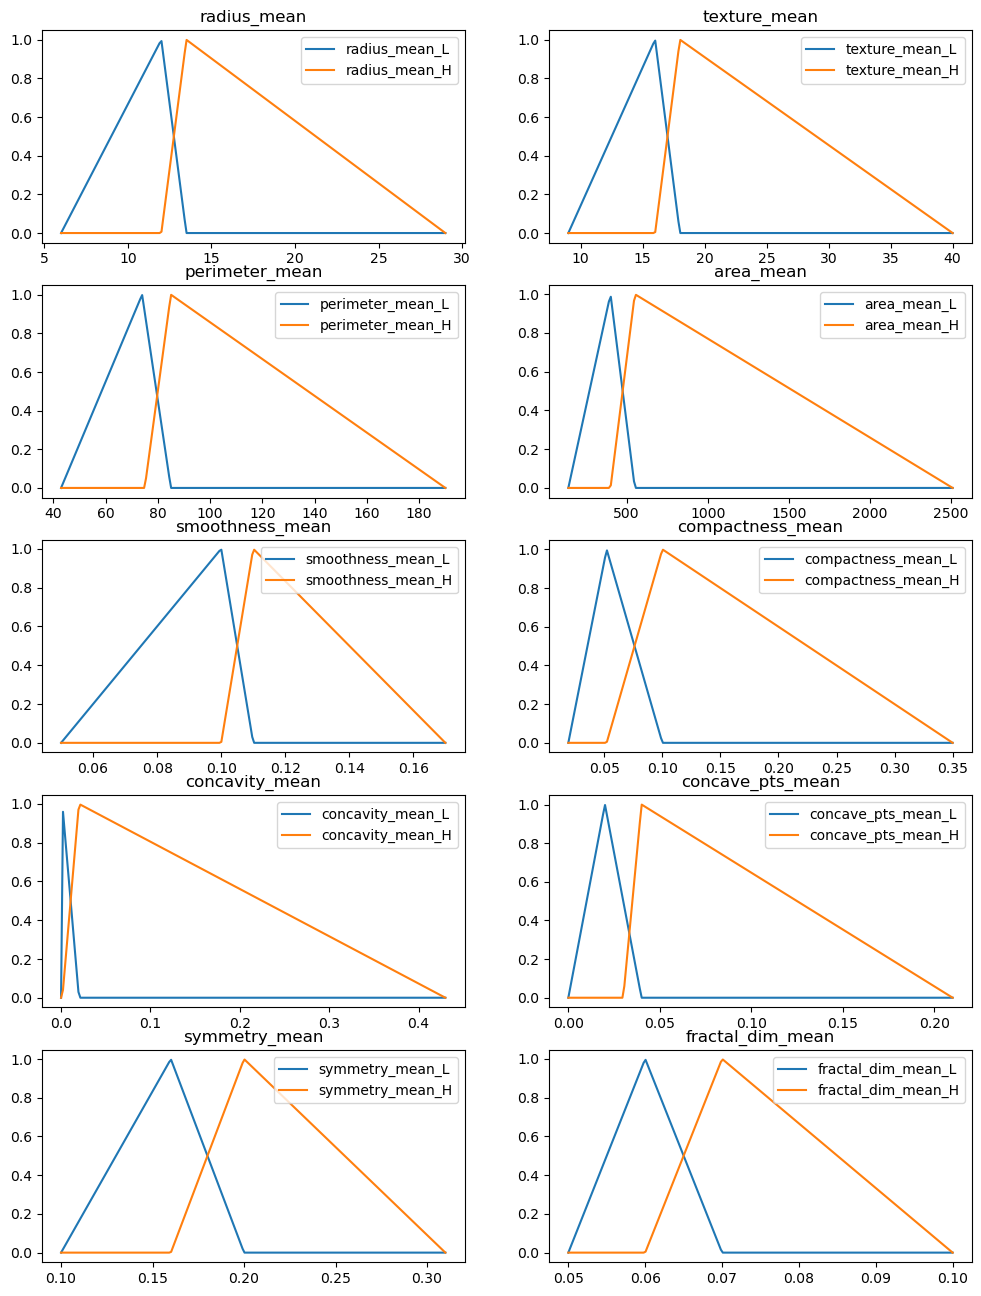

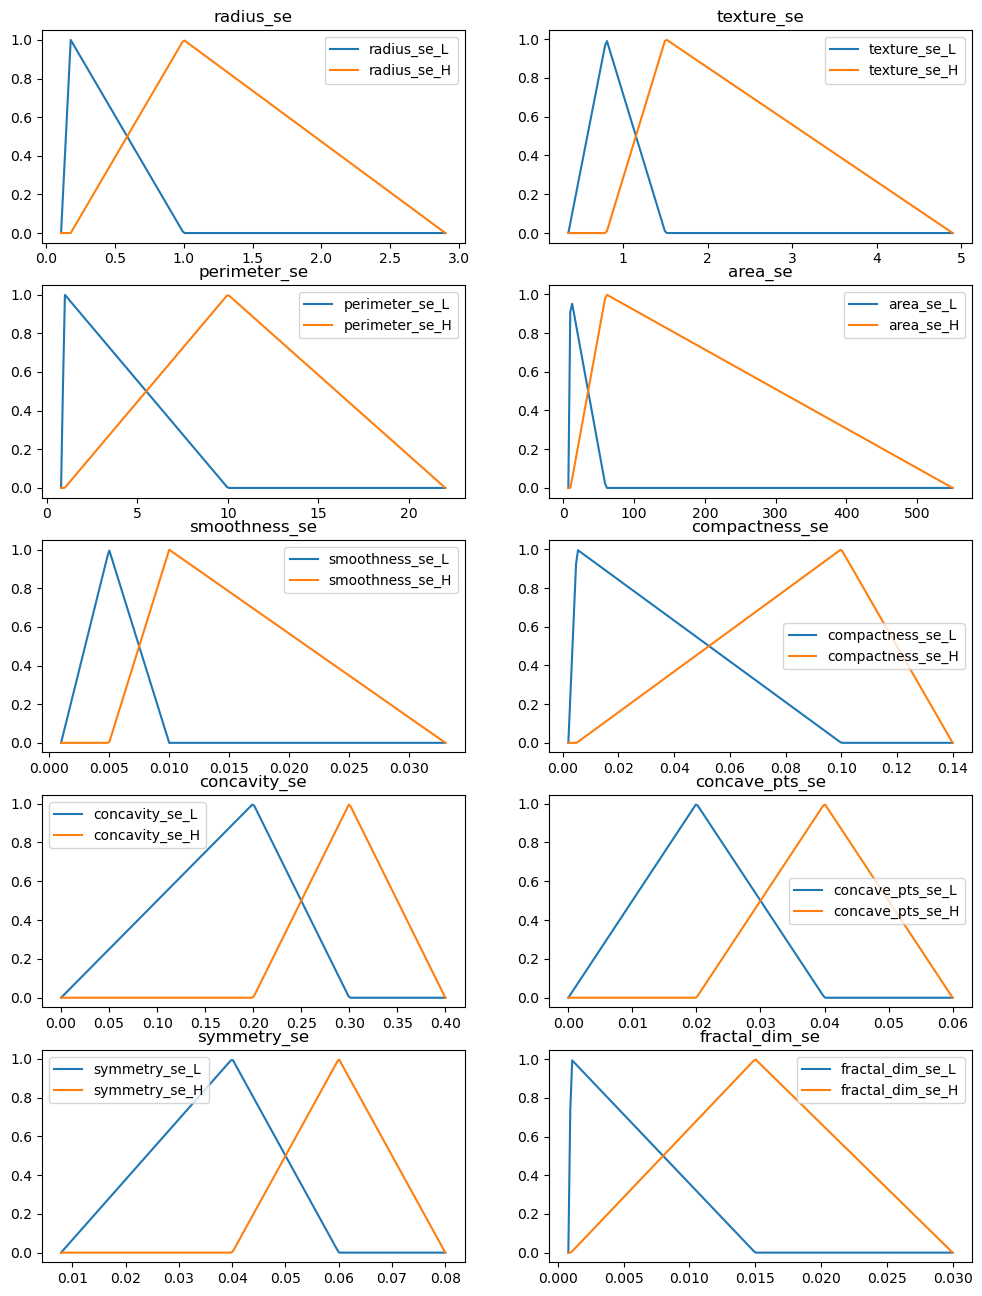

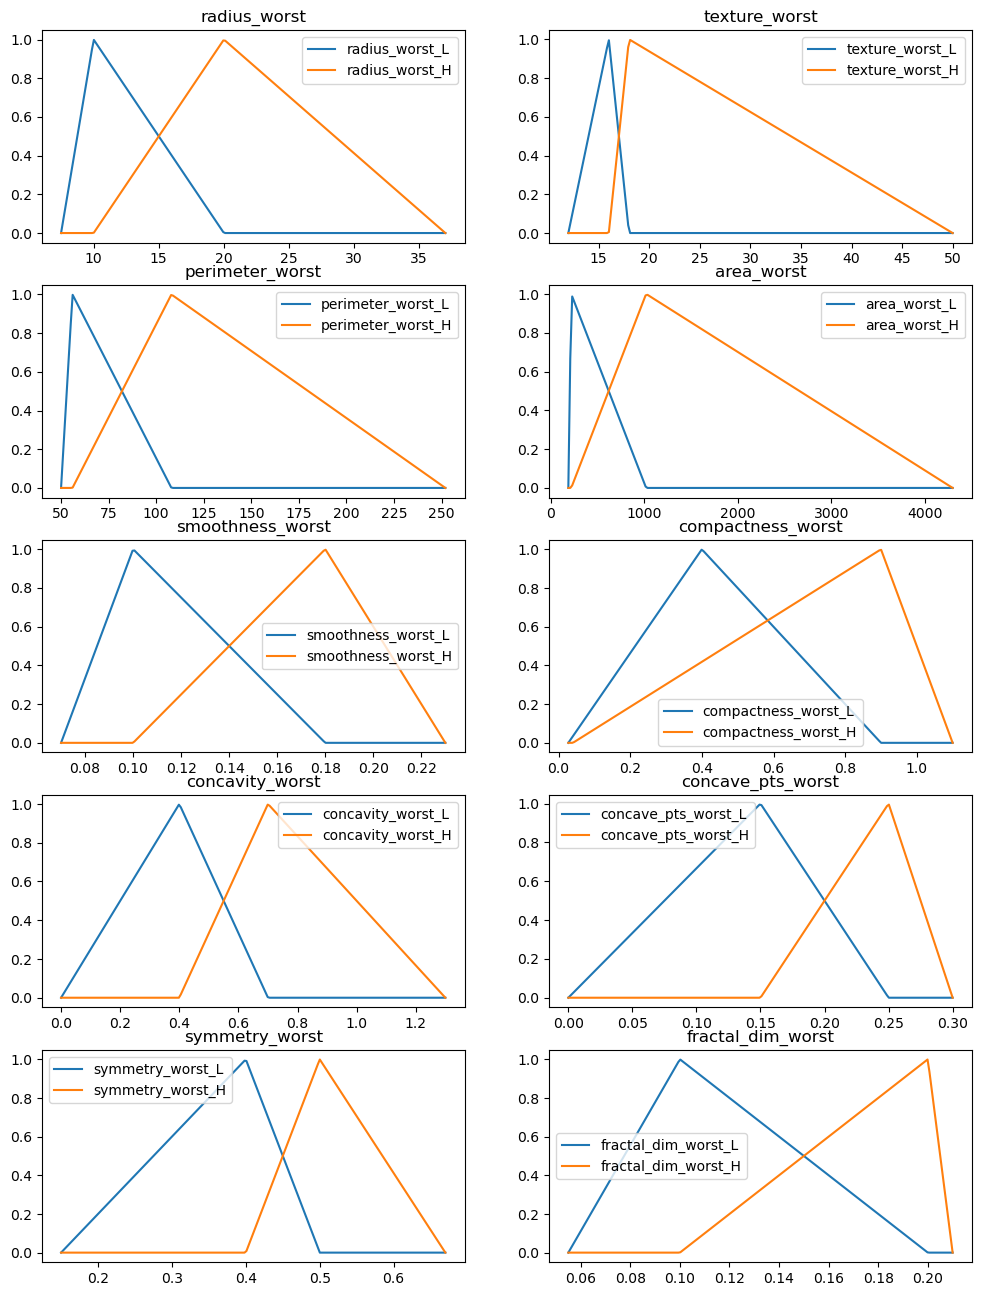

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages

# Define membership functions parameters
mf_params = {
    'radius_mean': [(6, 12, 13.5), (12, 13.5, 29)],
    'texture_mean': [(9, 16, 18), (16, 18, 40)],
    'perimeter_mean': [(43, 74, 85), (75, 85, 190)],
    'area_mean': [(140, 400, 550), (400, 550, 2510)],
    'smoothness_mean': [(0.05, 0.1, 0.11), (0.1, 0.11, 0.17)],
    'compactness_mean': [(0.019, 0.052, 0.1), (0.052, 0.1, 0.35)],
    'concavity_mean': [(0, 0.0014, 0.02), (0.0014, 0.02, 0.43)],
    'concave_pts_mean': [(0, 0.02, 0.04), (0.03, 0.04, 0.21)],
    'symmetry_mean': [(0.100, 0.16, 0.2), (0.16, 0.2, 0.31)],
    'fractal_dim_mean': [(0.05, 0.06, 0.07), (0.06, 0.07, 0.1)],
    'radius_se': [(0.11, 0.18, 1), (0.18, 1, 2.9)],
    'texture_se': [(0.35, 0.8, 1.5), (0.8, 1.5, 4.9)],
    'perimeter_se': [(0.8, 1, 10), (1, 10, 22)],
    'area_se': [(7, 10, 60), (10, 60, 550)],
    'smoothness_se': [(0.001, 0.005, 0.01), (0.005, 0.01, 0.033)],
    'compactness_se': [(0.002, 0.005, 0.1), (0.005, 0.1, 0.14)],
    'concavity_se': [(0, 0.2, 0.3), (0.2, 0.3, 0.4)],
    'concave_pts_se': [(0, 0.02, 0.04), (0.02, 0.04, 0.06)],
    'symmetry_se': [(0.007882, 0.04, 0.06), (0.04, 0.06, 0.08)],
    'fractal_dim_se': [(0.0008, 0.001, 0.015), (0.001, 0.015, 0.03)],
    'radius_worst': [(7.5, 10, 20), (10, 20, 37)],
    'texture_worst': [(12, 16, 18), (16, 18, 50)],
    'perimeter_worst': [(50, 56, 108), (56, 108, 252)],
    'area_worst': [(185, 216, 1018), (216, 1018, 4300)],
    'smoothness_worst': [(0.07, 0.1, 0.18), (0.1, 0.18, 0.23)],
    'compactness_worst': [(0.02729, 0.4, 0.9), (0.04, 0.9, 1.1)],
    'concavity_worst': [(0, 0.4, 0.7), (0.4, 0.7, 1.3)],
    'concave_pts_worst': [(0, 0.15, 0.25), (0.15, 0.25, 0.3)],
    'symmetry_worst': [(0.15, 0.4, 0.5), (0.4, 0.5, 0.67)],
    'fractal_dim_worst': [(0.055, 0.1, 0.2), (0.1, 0.2, 0.21)]
}

def triangular(x, a, b, c):
    return np.where(x <= a, 0,
                    np.where(x <= b, (x - a) / (b - a),
                             np.where(x < c, (c - x) / (c - b), 0)))

# Prepare groups of 10 features each
features = list(mf_params.keys())
groups = [features[i:i+10] for i in range(0, len(features), 10)]

# Save all plots into a single PDF
pdf_path = "/Users/joshuakirubancruzs/Documents/Work/VIT/CONFERENCE/IIITG/membership_plots.pdf"
with PdfPages(pdf_path) as pdf:
    for feature_list in groups:
        fig, axes = plt.subplots(5, 2, figsize=(12, 16))
        axes = axes.flatten()
        for ax, feature in zip(axes, feature_list):
            a1, b1, c1 = mf_params[feature][0]
            a2, b2, c2 = mf_params[feature][1]
            x = np.linspace(a1, c2, 200)
            y1 = triangular(x, a1, b1, c1)
            y2 = triangular(x, a2, b2, c2)
            ax.plot(x, y1, label=f"{feature}_L")
            ax.plot(x, y2, label=f"{feature}_H")
            ax.set_title(feature)
            ax.legend()
        # plt.tight_layout()
        # pdf.savefig(fig)
        # plt.close(fig)

print(f"Saved membership function plots to PDF: {pdf_path}")
